# Sincronización de sEMG y captura de movimiento (MVNX)

**Proyecto Integrador — Equipo 1**

**Objetivo:** empatar en el tiempo las dos fuentes del dataset (las envolventes sEMG y la captura de movimiento Xsens MVNX) y exportarlas sobre una **rejilla temporal común**, para que los modelos (por ejemplo, CPC) puedan usar ambas modalidades a la vez.

**Punto de partida** (`00_EDA_dataset_v2.ipynb`, sección 9.7):

- **Emparejamiento:** cada ensayo sEMG tiene su grabación MVNX (por sujeto, tarea, carga, condición y lado).
- **Los relojes no coinciden:** difieren ~1 hora, más un desfase residual que cambia de ensayo a ensayo (de −31 a +31 s). Restar 3600 s no basta.
- **Pero las etiquetas sí coinciden:** en los 641 pares válidos, sEMG y MVNX tienen **la misma secuencia de actividades**, y un **desfase constante por par** explica los límites de las etiquetas con un error típico de ~1 ms. Esto es, cada sistema tiene su propio reloj. Cada par (sEMG vs MVNX) tiene un solo desfase, y la diferencia es casi idéntica, por lo que bastaría con restar el número de tiempos entre ensayos para conseguir una alineación. 

### Decisiones de diseño

| Tema | Decisión |
| :--- | :--- |
| Alineación | Desfase constante por par, estimado con los **eventos de las etiquetas** (inicios y fines de actividad), y **validado** con una correlación independiente entre la actividad sEMG y el movimiento |
| Validación | Si la señal no confirma el desfase de los eventos, el ensayo **se conserva y se marca** |
| Rejilla común | Configurable (`TARGET_FS`), **12 Hz** por defecto |
| Tramo temporal | Sólo donde hay **ambas** modalidades (intersección) |
| sEMG | `Norm_RMS` (envolvente en %MVC), con el mismo filtro antialias que el avance 2 |
| MVNX | **Todas** las variables (15 campos, ~780 columnas); donde una grabación no tiene una variable, queda vacía (NaN) |
| Remuestreo MVNX | Filtro pasa-bajas antialias de fase cero y después interpolación. Rotaciones con tratamiento especial: ángulos "desenrollados" y cuaterniones con interpolación esférica (*slerp*) |
| Eje de tiempo MVNX | Marcas de tiempo **reales** de cada frame (no 240 Hz nominal) |
| Ensayos bimanuales | Un registro con **16 canales sEMG** (8 de cada brazo) y su MVNX, en un **conjunto separado** del de un brazo |
| Etiquetas | **Ambas** (sEMG y MVNX), y una marca de dónde coinciden |
| Base de los índices MVNX | **Verificada con los datos** (sección 4) |
| Exclusiones | Se excluyen los archivos que el EDA marcó; un bimanual con un brazo roto se excluye completo |
| Partición | Como el avance 2: entrenamiento 1–10, validación 11–12, prueba 13–14 |

### Salida

`notebooks/_cache/sync/fs{TARGET_FS}/` con dos conjuntos: **`un_brazo/`** (ensayos isocinéticos y MMH a una mano, 8 canales sEMG) y **`bimanual/`** (MMH bimanual, 16 canales). Cada uno contiene:

- `series.npz`: series continuas alineadas;
- `trials.csv`: un renglón por ensayo, con su desfase y su validación;
- `columns.json`: nombre y unidad de cada columna.

Además, `metadata.json` y `exclusiones.csv` a nivel global. La sección 9 incluye una función para leerlos.

# 1. Configuración

La lectura de los MVNX (53 GB de XML) se hace en paralelo y su resultado se guarda **por ensayo** en `_cache/sync/fs{TARGET_FS}/_ensayos/`. Si se interrumpe, al volver a ejecutar sólo se procesan los ensayos que faltan. Con `REFRESH = True` se recalcula todo.

Con `QUICK = True` se procesan sólo unos pocos ensayos, en una carpeta aparte, para comprobar que todo funciona.

In [1]:
import json
import re
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from scipy.interpolate import interp1d
from scipy.signal import butter, correlate, correlation_lags, sosfiltfilt
from scipy.spatial.transform import Rotation, Slerp

# ----------------------------- Parámetros -----------------------------
TARGET_FS = 12                  # Hz de la rejilla común (12, 25, 50, ...)
QUICK = False                   # True = prueba con pocos ensayos, en una carpeta aparte
REFRESH = False                 # True = recalcular aunque exista la caché por ensayo
N_JOBS = 8                      # procesos en paralelo para leer los MVNX
ANTIALIAS_RATIO = 0.4           # corte del pasa-bajas = 0.4 · TARGET_FS (80 % de Nyquist), como el avance 2
ANTIALIAS_ORDER = 4             # Butterworth de orden 4, aplicado ida y vuelta (fase cero)
EMG_ANTIALIAS_BELOW_FS = 25     # sEMG: filtrar sólo si TARGET_FS < 25 Hz (misma regla que el avance 2)
VALIDATION_FS = 20              # Hz para la correlación sEMG–movimiento
VALIDATION_MAX_LAG_S = 45       # búsqueda del desfase por señal: ± 45 s alrededor de 0
VALIDATION_FLAG_S = 1.0         # se marca el ensayo si señal y eventos difieren más de esto (precisión de la señal ~1 s)
SPLITS = {"train": range(1, 11), "validation": (11, 12), "test": (13, 14)}
# ----------------------------------------------------------------------

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_ROOT = REPO_DIR / "datos_unzipped"
EMG_DIR, EMG_LABEL_DIR = DATA_ROOT / "Data", DATA_ROOT / "Labels"
MVNX_DIR, MVNX_LABEL_DIR = DATA_ROOT / "mvnx_files", DATA_ROOT / "Labels 2"
CACHE_DIR = REPO_DIR / "notebooks" / "_cache"
EXPORT_DIR = CACHE_DIR / "sync" / (f"fs{TARGET_FS}" + ("_quick" if QUICK else ""))
TRIAL_CACHE = EXPORT_DIR / "_ensayos"
TRIAL_CACHE.mkdir(parents=True, exist_ok=True)
for d in (EMG_DIR, EMG_LABEL_DIR, MVNX_DIR, MVNX_LABEL_DIR):
    assert d.exists(), f"No se encontró {d}"

LABEL_ORDER = ["N", "LF", "K", "PT", "LT", "W", "PF"]
LABEL_TO_ID = {l: i for i, l in enumerate(LABEL_ORDER)}
NORM_RMS = [f"Norm_RMS_{i}" for i in range(1, 9)]
NS = "{http://www.xsens.com/mvn/mvnx}"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
print(f"TARGET_FS = {TARGET_FS} Hz | QUICK = {QUICK} | exportación: {EXPORT_DIR.relative_to(REPO_DIR)}")

TARGET_FS = 12 Hz | QUICK = False | exportación: notebooks/_cache/sync/fs12


# 2. Catálogo y emparejamiento

Los nombres de archivo codifican sujeto, tarea, lado, carga y condición. Las reglas de emparejamiento son las del EDA v2:

- **Isocinéticos y MMH a una mano:** 1 sEMG ↔ 1 MVNX, con el **mismo lado**.
- **MMH bimanual:** el MVNX **no tiene lado** y corresponde a **dos** sEMG, el del brazo izquierdo y el del derecho.

Las grabaciones de MVC (contracción máxima) no son actividades y se omiten.

In [2]:
EMG_RE = re.compile(r"Subj_(?P<subject>\d+)_(?:(?P<mvc>MVC)_)?(?P<task>Isokin|MMH_Bim|MMH_One|All)_(?P<side>[LR])"
                    r"(?:_(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d))?_EMG_data\.csv")
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def parse(paths, regex):
    rows = []
    for p in sorted(paths):
        m = regex.fullmatch(p.name)
        if m is None:
            raise ValueError(f"Nombre inesperado: {p.name}")
        d = m.groupdict()
        rows.append({"file": p.name, "path": p, "subject": int(d["subject"]), "task": d["task"], "side": d["side"],
                     "load_kg": int(d["load_kg"]) if d["load_kg"] else None, "condition": d["condition"],
                     "is_mvc": bool(d.get("mvc"))})
    return pd.DataFrame(rows)


emg = parse(EMG_DIR.glob("Subj_*/*.csv"), EMG_RE)
emg = emg[~emg["is_mvc"]].reset_index(drop=True)
emg["label_path"] = [EMG_LABEL_DIR / p.parent.name / p.name.replace("_EMG_data.csv", "_EMG_labels.csv") for p in emg["path"]]
mvnx = parse(MVNX_DIR.glob("Subj_*/*.mvnx"), MVNX_RE)
mvnx["label_path"] = [MVNX_LABEL_DIR / p.parent.name / f"{p.stem}_mvnx_labels.csv" for p in mvnx["path"]]
assert emg["label_path"].map(Path.exists).all() and mvnx["label_path"].map(Path.exists).all(), "Faltan archivos de etiquetas"

KEYS = ["subject", "task", "load_kg", "condition"]
trials = []
for r in mvnx.itertuples(index=False):
    match = emg[(emg["subject"] == r.subject) & (emg["task"] == r.task) & (emg["load_kg"] == r.load_kg) & (emg["condition"] == r.condition)]
    if isinstance(r.side, str):
        match = match[match["side"] == r.side]
    trials.append({"mvnx_file": r.file, "mvnx_path": r.path, "mvnx_label_path": r.label_path, "subject": r.subject,
                   "task": r.task, "side": r.side if isinstance(r.side, str) else "LR", "load_kg": r.load_kg, "condition": r.condition,
                   "conjunto": "bimanual" if r.task == "MMH_Bim" else "un_brazo",
                   "emg": {m.side: {"file": m.file, "path": m.path, "label_path": m.label_path} for m in match.itertuples()}})
trials = pd.DataFrame(trials)
trials["n_emg"] = trials["emg"].map(len)
expected = np.where(trials["conjunto"] == "bimanual", 2, 1)
paired_emg = {e["file"] for d in trials["emg"] for e in d.values()}
print(f"{len(mvnx)} MVNX | {len(emg)} sEMG de ensayos | sEMG sin MVNX: {len(set(emg['file']) - paired_emg)} | "
      f"MVNX con emparejamiento incompleto: {(trials['n_emg'] != expected).sum()}")
display(trials.groupby(["conjunto", "task"]).agg(ensayos=("mvnx_file", "size"), sujetos=("subject", "nunique"),
                                                  archivos_sEMG=("n_emg", "sum")))

517 MVNX | 643 sEMG de ensayos | sEMG sin MVNX: 0 | MVNX con emparejamiento incompleto: 0


ensayos  sujetos  archivos_sEMG
conjunto task                                    
bimanual MMH_Bim      126       14            252
un_brazo Isokin       223       14            223
         MMH_One      168       14            168

# 3. Exclusiones

Se excluyen los mismos archivos que el EDA marcó, con la misma regla:

| Motivo | Regla |
| :--- | :--- |
| sEMG con canales rotos | Desviación estándar cruda > 50 mV en algún canal (EDA, sección 6) |
| Etiquetas inconsistentes (sEMG o MVNX) | Algún segmento vacío o invertido, o solapado con el siguiente |
| MVNX con saltos de tiempo | Algún intervalo entre frames mayor que un periodo + 1.1 ms (se detecta al leer los MVNX, sección 4) |
| Secuencias distintas | La secuencia de actividades de sEMG y MVNX no coincide, así que no se puede alinear por eventos |

En los **ensayos bimanuales**, si se excluye cualquiera de los dos brazos, se excluye **el ensayo completo**.

In [3]:
def labels_ok(path):
    lab = pd.read_csv(path)
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABEL_ORDER).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


stats = pd.read_csv(CACHE_DIR / "emg_file_stats.csv")
std_max_mV = stats[[f"raw_std_{c}" for c in range(1, 9)]].max(axis=1) * 1e3
BROKEN_EMG = set(stats.loc[std_max_mV > 50, "file"])

exclusions = []
for r in trials.itertuples():
    for side, e in r.emg.items():
        if e["file"] in BROKEN_EMG:
            exclusions.append({"mvnx_file": r.mvnx_file, "motivo": f"sEMG {side} con canales rotos ({e['file']})"})
        if not labels_ok(e["label_path"]):
            exclusions.append({"mvnx_file": r.mvnx_file, "motivo": f"etiquetas sEMG {side} inconsistentes ({e['file']})"})
    if not labels_ok(r.mvnx_label_path):
        exclusions.append({"mvnx_file": r.mvnx_file, "motivo": "etiquetas MVNX inconsistentes"})
    if r.n_emg != (2 if r.conjunto == "bimanual" else 1):
        exclusions.append({"mvnx_file": r.mvnx_file, "motivo": "emparejamiento sEMG incompleto"})
exclusions = pd.DataFrame(exclusions, columns=["mvnx_file", "motivo"])
display(exclusions)
candidates = trials[~trials["mvnx_file"].isin(exclusions["mvnx_file"])].reset_index(drop=True)
if QUICK:   # unos pocos ensayos de cada conjunto y tarea, de sujetos al azar
    candidates = candidates.groupby(["conjunto", "task"], group_keys=False).sample(4, random_state=0).reset_index(drop=True)
print(f"{len(candidates)} ensayos pasan a la lectura de MVNX ({trials['mvnx_file'].isin(exclusions['mvnx_file']).sum()} excluidos)")

,mvnx_file,motivo
0,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,etiquetas sEMG R inconsistentes (Subj_02_MMH_O...
1,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,etiquetas MVNX inconsistentes
2,Subj_05_Isokin_L_04kg_80bpm.mvnx,etiquetas sEMG L inconsistentes (Subj_05_Isoki...
3,Subj_05_Isokin_L_04kg_80bpm.mvnx,etiquetas MVNX inconsistentes
4,Subj_07_MMH_Bim_08kg_Trial_3.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_08...
5,Subj_07_MMH_Bim_12kg_Trial_1.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_12...
6,Subj_07_MMH_Bim_12kg_Trial_2.mvnx,sEMG R con canales rotos (Subj_07_MMH_Bim_R_12...


512 ensayos pasan a la lectura de MVNX (5 excluidos)


# 4. Alineación por eventos de las etiquetas

### Idea

Ambas etiquetas marcan los mismos eventos (cada inicio y fin de actividad), cada una con el reloj de su sistema. Si para cada evento se resta el tiempo MVNX del tiempo sEMG, se obtiene el **desfase** entre ambos relojes. Si el desfase es **el mismo para todos los eventos** del ensayo (residuo pequeño), basta un corrimiento constante para alinear las señales.

$$\text{desfase}_k = t^{\text{sEMG}}_k - t^{\text{MVNX}}_k, \qquad \text{desfase del ensayo} = \operatorname{mediana}_k(\text{desfase}_k)$$

- **Tiempos sEMG:** columna `Time` del CSV (ms), relativa a la primera fila.
- **Tiempos MVNX:** atributo `time` de cada frame normal (ms reales, no 240 Hz nominal), relativo al primer frame normal.

Esta primera pasada lee sólo los **tiempos** de los frames MVNX (sin sus valores), que es rápido. También detecta los saltos de tiempo para la exclusión.

### ¿Los índices de las etiquetas MVNX empiezan en 0 o en 1?

Los CSV no lo dicen. **La alineación por eventos no puede distinguirlo:** cambiar la base mueve todos los límites un frame a la vez, y ese corrimiento constante queda absorbido por el desfase. La única evidencia en los datos son los **extremos**:

- una etiqueta que **empieza en el frame 0** sólo es válida con base 0;
- una que **termina en el frame `n`** (el número de frames) sólo es válida con base 1.

Se cuentan ambos casos en todas las grabaciones. Si la evidencia no es concluyente, se usa base 0 (la de los índices XML) y se reporta. El impacto máximo de equivocarse es **1 frame (~4 ms)**, muy por debajo de un paso de la rejilla (83 ms a 12 Hz).

In [4]:
def mvnx_frame_times(path):
    """Tiempos (s, relativos) de los frames normales, sin leer sus valores."""
    times = []
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            if event == "start" and el.tag == NS + "frames":
                frames = el
            elif event == "end" and el.tag == NS + "frame":
                if el.get("type") == "normal":
                    times.append(float(el.get("time")))
                frames.remove(el)
    t = np.asarray(times) / 1000.0
    return t - t[0]


def emg_times(path):
    tm = pd.read_csv(path, usecols=["Time"])["Time"].to_numpy(dtype=np.float64)
    return (tm - tm[0]) / 1000.0


def event_alignment(t_emg, lab_emg, t_mv, lab_mv, mv_base):
    """Desfase por evento (inicio y fin de cada segmento) entre sEMG y MVNX."""
    if list(lab_emg["Label"]) != list(lab_mv["Label"]):
        return None
    s_mv, e_mv = lab_mv["Start_Frame"].to_numpy() - mv_base, lab_mv["End_Frame"].to_numpy() - mv_base
    if (s_mv < 0).any() or (e_mv >= len(t_mv)).any():
        return None
    s_emg, e_emg = lab_emg["Start_Frame"].to_numpy(), lab_emg["End_Frame"].to_numpy()
    offsets = np.concatenate([t_emg[s_emg] - t_mv[s_mv], t_emg[e_emg] - t_mv[e_mv]])
    off = float(np.median(offsets))
    resid = np.abs(offsets - off)
    return {"offset_s": off, "residual_median_ms": 1000 * float(np.median(resid)),
            "residual_p95_ms": 1000 * float(np.quantile(resid, 0.95)), "n_events": len(offsets)}


def pass1(row):
    t_mv = mvnx_frame_times(row.mvnx_path)
    dt_ms = np.diff(t_mv) * 1000
    lab_mv = pd.read_csv(row.mvnx_label_path)
    out = {"mvnx_file": row.mvnx_file, "n_frames": len(t_mv), "duration_mv_s": float(t_mv[-1]),
           "fs_mv_real": float((len(t_mv) - 1) / t_mv[-1]), "n_time_gaps": int((dt_ms > 1000 / 240 + 1.1).sum()),
           "mv_start_is_0": bool((lab_mv["Start_Frame"] == 0).any()),
           "mv_end_is_n": bool((lab_mv["End_Frame"] == len(t_mv)).any())}
    for side, e in row.emg.items():
        t_emg = emg_times(e["path"])
        lab_emg = pd.read_csv(e["label_path"])
        out[f"duration_emg_{side}_s"] = float(t_emg[-1])
        out[f"fs_emg_{side}"] = float((len(t_emg) - 1) / t_emg[-1])
        for base in (0, 1):
            res = event_alignment(t_emg, lab_emg, t_mv, lab_mv, base)
            for k, v in (res or {"offset_s": np.nan}).items():
                out[f"{k}_{side}_base{base}"] = v
    return out


t0 = time.time()
p1 = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(pass1)(r) for r in candidates.itertuples(index=False)))
print(f"Primera pasada (tiempos y eventos): {time.time() - t0:.0f} s")

# --- Base de los índices MVNX: evidencia en los extremos ---
n0, n1 = int(p1["mv_start_is_0"].sum()), int(p1["mv_end_is_n"].sum())
if n0 > 0 and n1 == 0:
    MV_BASE, base_reason = 0, f"{n0} grabaciones tienen una etiqueta que empieza en el frame 0 (sólo válido con base 0)"
elif n1 > 0 and n0 == 0:
    MV_BASE, base_reason = 1, f"{n1} grabaciones tienen una etiqueta que termina en el frame n (sólo válido con base 1)"
else:
    MV_BASE, base_reason = 0, (f"evidencia no concluyente (empieza en 0: {n0}; termina en n: {n1}); se usa base 0, "
                               "como los índices XML. Impacto máximo: 1 frame (~4 ms)")
print(f"Base de los índices MVNX = {MV_BASE}: {base_reason}")

Primera pasada (tiempos y eventos): 39 s
Base de los índices MVNX = 0: evidencia no concluyente (empieza en 0: 0; termina en n: 0); se usa base 0, como los índices XML. Impacto máximo: 1 frame (~4 ms)


### Calidad de la alineación por eventos

Para cada brazo de cada ensayo:

- **desfase:** cuánto adelanta el reloj sEMG al MVNX;
- **residuo:** cuánto se desvía cada evento del desfase del ensayo. Con un residuo de unos pocos milisegundos, un corrimiento constante explica todos los eventos.

Los ensayos con saltos de tiempo en el MVNX, o cuya secuencia de actividades no coincide (sin desfase), se excluyen aquí.

505 ensayos alineados por eventos (627 pares brazo–MVNX)


,desfase [s],residuo mediano [ms],residuo p95 [ms],eventos
count,627.00,627.00,627.00,627.00
mean,11.83,0.48,1.27,32.98
std,5.49,0.14,0.22,8.54
min,-31.46,0.00,0.68,8.00
25%,10.38,0.39,1.13,32.00
50%,12.01,0.48,1.27,38.00
75%,14.53,0.56,1.41,38.00
max,31.66,1.05,1.98,38.00


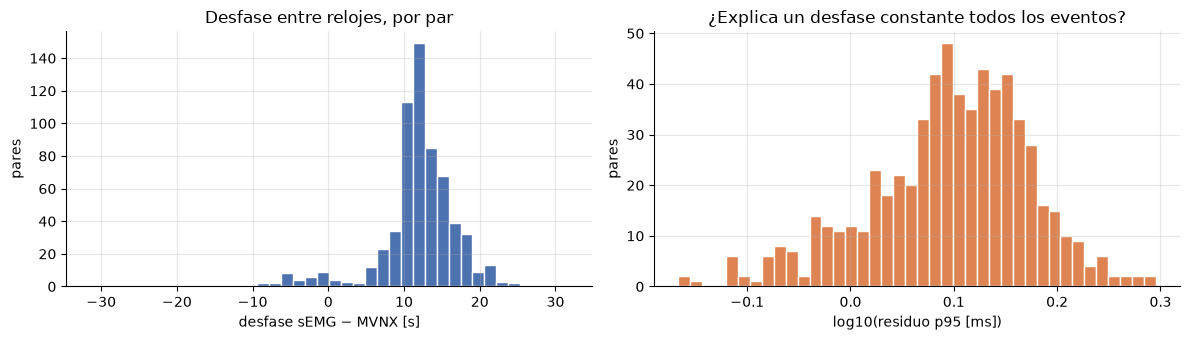

In [5]:
aligned = candidates.merge(p1, on="mvnx_file")
for r in aligned.itertuples():
    if r.n_time_gaps > 0:
        exclusions.loc[len(exclusions)] = [r.mvnx_file, f"MVNX con {r.n_time_gaps} saltos de tiempo"]
    for side in r.emg:
        if pd.isna(getattr(r, f"offset_s_{side}_base{MV_BASE}")):
            exclusions.loc[len(exclusions)] = [r.mvnx_file, f"secuencias de actividad distintas (sEMG {side})"]
aligned = aligned[~aligned["mvnx_file"].isin(exclusions["mvnx_file"])].reset_index(drop=True)

long = []
for r in aligned.itertuples():
    for side in r.emg:
        long.append({"mvnx_file": r.mvnx_file, "conjunto": r.conjunto, "brazo": side,
                     "desfase [s]": getattr(r, f"offset_s_{side}_base{MV_BASE}"),
                     "residuo mediano [ms]": getattr(r, f"residual_median_ms_{side}_base{MV_BASE}"),
                     "residuo p95 [ms]": getattr(r, f"residual_p95_ms_{side}_base{MV_BASE}"),
                     "eventos": getattr(r, f"n_events_{side}_base{MV_BASE}")})
events = pd.DataFrame(long)
print(f"{len(aligned)} ensayos alineados por eventos ({len(events)} pares brazo–MVNX)")
display(events.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(events["desfase [s]"], bins=40, color="#4c72b0", edgecolor="white")
axes[0].set(xlabel="desfase sEMG − MVNX [s]", ylabel="pares", title="Desfase entre relojes, por par")
axes[1].hist(np.log10(events["residuo p95 [ms]"].clip(lower=0.1)), bins=40, color="#dd8452", edgecolor="white")
axes[1].set(xlabel="log10(residuo p95 [ms])", ylabel="pares", title="¿Explica un desfase constante todos los eventos?")
plt.tight_layout()
plt.show()

# 5. Lectura completa, validación con la señal y remuestreo

Para cada ensayo (en paralelo), la función `process_trial`:

1. **Lee el MVNX completo:** los 15 campos de cada frame normal, con los nombres de segmentos, sensores, articulaciones y contactos de su cabecera.
2. **Valida el desfase con la señal**, de forma **independiente** de las etiquetas:
   - **actividad muscular:** el promedio de los 8 canales `Norm_RMS`;
   - **movimiento:** tres señales MVNX distintas:
     - la suma de las velocidades angulares de los 23 segmentos (cuánto se mueve el cuerpo);
     - la flexión del codo del brazo con sEMG;
     - una combinación de postura: altura de la mano, ángulo del hombro y flexión del tronco.

   Cada señal se lleva a 20 Hz con su propio reloj. Para cada una se busca el desfase que maximiza su correlación con la actividad muscular (±45 s). La estimación por señal es la **mediana de las tres**: las tareas son cíclicas y una sola señal puede confundirse de ciclo (errores de ±10 o ±20 s), pero es raro que se confundan dos de tres. Si la mediana difiere del desfase de los eventos en más de `VALIDATION_FLAG_S`, el ensayo **se marca**, pero se conserva.
3. **Define la rejilla común** sobre el reloj MVNX: desde que empiezan **todas** las señales hasta que termina la primera, cada `1 / TARGET_FS` s. Los tiempos sEMG se trasladan con su desfase.
4. **Remuestrea** cada tipo de variable con su tratamiento:

| Tipo | Campos | Tratamiento |
| :--- | :--- | :--- |
| sEMG | `Norm_RMS` (8 o 16) | Pasa-bajas antialias si `TARGET_FS` < 25 Hz (como el avance 2) e interpolación lineal |
| Continuas | posición, velocidad, aceleración, velocidad y aceleración angular, aceleración libre y campo magnético de los sensores, centro de masa | Pasa-bajas antialias (Butterworth de orden 4, corte 0.4 · `TARGET_FS`, fase cero) e interpolación lineal |
| Ángulos (°) | `jointAngle`, `jointAngleXZY`, `jointAngleErgo`, `jointAngleErgoXZY` | **Desenrollar** (eliminar los saltos ±180°) → antialias → interpolación → volver a (−180°, 180°] |
| Cuaterniones | `orientation` (segmentos), `sensorOrientation` | **Signo consistente** (q y −q son la misma rotación) → antialias por componente y renormalización → **interpolación esférica (slerp)** |
| Binarias | `footContacts` | Frame más cercano (no se promedian valores 0/1) |

5. **Asigna las etiquetas** a cada instante de la rejilla: la del sEMG (de cada brazo) y la del MVNX, tomando la muestra más cercana; −1 significa "sin etiqueta".

El resultado de cada ensayo se guarda en `_ensayos/`; si ya existe, se reutiliza.

In [6]:
FIELD_KIND = {
    "position": "continua", "velocity": "continua", "acceleration": "continua", "angularVelocity": "continua",
    "angularAcceleration": "continua", "sensorFreeAcceleration": "continua", "sensorMagneticField": "continua",
    "centerOfMass": "continua", "jointAngle": "angulo", "jointAngleXZY": "angulo", "jointAngleErgo": "angulo",
    "jointAngleErgoXZY": "angulo", "orientation": "cuaternion", "sensorOrientation": "cuaternion", "footContacts": "binaria",
}
FIELD_UNIT = {  # Manual de usuario Xsens MVN, exportación MVNX
    "position": "m", "velocity": "m/s", "acceleration": "m/s²", "angularVelocity": "rad/s", "angularAcceleration": "rad/s²",
    "sensorFreeAcceleration": "m/s²", "sensorMagneticField": "u.a.", "centerOfMass": "m", "jointAngle": "°",
    "jointAngleXZY": "°", "jointAngleErgo": "°", "jointAngleErgoXZY": "°", "orientation": "cuaternión (w, x, y, z)",
    "sensorOrientation": "cuaternión (w, x, y, z)", "footContacts": "0/1",
}
FIELD_ORDER = list(FIELD_KIND)


def read_mvnx(path):
    """Cabecera (nombres) y todos los campos de los frames normales."""
    names = {"segment": [], "sensor": [], "joint": [], "ergonomicJointAngle": [], "contactDefinition": []}
    times, raw = [], {}
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":
                    times.append(float(el.get("time")))
                    for c in el:
                        raw.setdefault(c.tag[len(NS):], []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items() if k in FIELD_KIND}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


def column_names(field, width, names):
    xyz = ["x", "y", "z"]
    if field in ("orientation",):
        return [f"{field}__{s}__{q}" for s in names["segment"] for q in "wxyz"]
    if field == "sensorOrientation":
        return [f"{field}__{s}__{q}" for s in names["sensor"] for q in "wxyz"]
    if field in ("sensorFreeAcceleration", "sensorMagneticField"):
        return [f"{field}__{s}__{a}" for s in names["sensor"] for a in xyz]
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field in ("jointAngleErgo", "jointAngleErgoXZY"):
        return [f"{field}__{j}__c{c}" for j in names["ergonomicJointAngle"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    if field == "centerOfMass":
        return [f"{field}__{a}" for a in xyz][:width] if width == 3 else [f"{field}__{i}" for i in range(width)]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in xyz]


def lowpass(x, fs, cutoff):
    sos = butter(ANTIALIAS_ORDER, cutoff, btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


def resample_continuous(t, x, grid, fs):
    return interp1d(t, lowpass(x, fs, ANTIALIAS_RATIO * TARGET_FS), axis=0, assume_sorted=True)(grid)


def resample_angles(t, deg, grid, fs):
    unwrapped = np.rad2deg(np.unwrap(np.deg2rad(deg), axis=0))
    out = resample_continuous(t, unwrapped, grid, fs)
    return (out + 180.0) % 360.0 - 180.0


def resample_quaternions(t, q_flat, grid, fs):
    q = q_flat.reshape(len(t), -1, 4).copy()                       # (frames, cuerpos, [w, x, y, z])
    flip = np.einsum("tkc,tkc->tk", q[1:], q[:-1]) < 0              # signo continuo: q y -q son la misma rotación
    sign = np.concatenate([np.ones((1, q.shape[1])), np.cumprod(np.where(flip, -1.0, 1.0), axis=0)])
    q *= sign[..., None]
    q = lowpass(q, fs, ANTIALIAS_RATIO * TARGET_FS)
    q /= np.linalg.norm(q, axis=2, keepdims=True)
    out = np.empty((len(grid), q.shape[1], 4))
    for k in range(q.shape[1]):
        rot = Rotation.from_quat(q[:, k][:, [1, 2, 3, 0]])          # scipy usa (x, y, z, w)
        out[:, k] = Slerp(t, rot)(grid).as_quat()[:, [3, 0, 1, 2]]
    keep = np.einsum("gkc,gkc->gk", out[1:], out[:-1]) < 0          # mantener signo continuo en la salida
    out[1:] *= np.cumprod(np.where(keep, -1.0, 1.0), axis=0)[..., None]
    return out.reshape(len(grid), -1)


def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


def frame_labels(lab, n, base=0):
    y = np.full(n, -1, dtype=np.int8)
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABEL_TO_ID[name]
    return y


def signal_lag(t_emg, act, t_mv, mov):
    """Desfase sEMG − MVNX (s) que maximiza la correlación entre actividad muscular y movimiento."""
    ge, gm = np.arange(0, t_emg[-1], 1 / VALIDATION_FS), np.arange(0, t_mv[-1], 1 / VALIDATION_FS)
    a, b = np.log1p(np.interp(ge, t_emg, act)), np.log1p(np.interp(gm, t_mv, mov))
    a, b = (a - a.mean()) / a.std(), (b - b.mean()) / b.std()
    corr = correlate(a, b, mode="full") / correlate(np.ones_like(a), np.ones_like(b), mode="full")
    overlap = correlate(np.ones_like(a), np.ones_like(b), mode="full")
    lags = correlation_lags(len(a), len(b)) / VALIDATION_FS
    ok = (np.abs(lags) <= VALIDATION_MAX_LAG_S) & (overlap >= 0.5 * min(len(a), len(b)))   # al menos la mitad traslapada
    i = np.flatnonzero(ok)[np.argmax(corr[ok])]
    return float(lags[i]), float(corr[i])


def process_trial(row, mv_base):
    out_path = TRIAL_CACHE / f"{Path(row.mvnx_file).stem}.npz"
    meta_path = out_path.with_suffix(".json")
    if out_path.exists() and meta_path.exists() and not REFRESH:
        return json.loads(meta_path.read_text())
    t_mv, data, names = read_mvnx(row.mvnx_path)
    fs_mv = (len(t_mv) - 1) / t_mv[-1]
    y_mv = frame_labels(pd.read_csv(row.mvnx_label_path), len(t_mv), mv_base)
    n = len(t_mv)
    seg, jn = names["segment"], names["joint"]
    angular_speed = np.linalg.norm(data["angularVelocity"].reshape(n, -1, 3), axis=2).sum(axis=1)
    pos, ja = data["position"].reshape(n, -1, 3), data["jointAngle"].reshape(n, -1, 3)
    trunk = np.abs(ja[:, jn.index("jL5S1"), 2] - np.median(ja[:, jn.index("jL5S1"), 2]))

    def movement_signals(side):
        S = "Left" if side == "L" else "Right"
        elbow = ja[:, jn.index(f"j{S}Elbow"), 2]
        hand_z = pos[:, seg.index(f"{S}Hand"), 2] - pos[:, seg.index("Pelvis"), 2]
        shoulder = np.linalg.norm(ja[:, jn.index(f"j{S}Shoulder")], axis=1)
        scaled = lambda v: (v - v.min()) / max(np.ptp(v), 1e-9)
        return {"vel_angular": angular_speed, "codo": scaled(elbow) + 1e-3,
                "postura": scaled(hand_z) + scaled(shoulder) + scaled(trunk) + 1e-3}

    sides = ["L", "R"] if row.conjunto == "bimanual" else [row.side]
    meta = {"mvnx_file": row.mvnx_file, "fs_mv_real": fs_mv}
    emg_sig, lo, hi = {}, [t_mv[0]], [t_mv[-1]]
    for side in sides:
        e = row.emg[side]
        d = pd.read_csv(e["path"], usecols=["Time"] + NORM_RMS)
        t_e = (d["Time"].to_numpy(np.float64) - d["Time"].iloc[0]) / 1000.0
        x_e = d[NORM_RMS].to_numpy(np.float64)
        fs_e = (len(t_e) - 1) / t_e[-1]
        off = getattr(row, f"offset_s_{side}_base{mv_base}")
        lags = {k: signal_lag(t_e, x_e.mean(axis=1), t_mv, v) for k, v in movement_signals(side).items()}
        lag = float(np.median([l for l, _ in lags.values()]))
        meta.update({f"emg_file_{side}": e["file"], f"fs_emg_{side}": fs_e, f"offset_event_{side}_s": off,
                     f"offset_signal_{side}_s": lag, f"corr_signal_{side}": float(np.median([c for _, c in lags.values()])),
                     f"diff_signal_event_{side}_s": lag - off,
                     **{f"diff_{k}_{side}_s": l - off for k, (l, _) in lags.items()}})
        if TARGET_FS < EMG_ANTIALIAS_BELOW_FS:
            x_e = lowpass(x_e, fs_e, ANTIALIAS_RATIO * TARGET_FS)
        emg_sig[side] = (t_e - off, x_e, frame_labels(pd.read_csv(e["label_path"]), len(t_e)))   # tiempos en el reloj MVNX
        lo.append(t_e[0] - off)
        hi.append(t_e[-1] - off)

    start, end = max(lo), min(hi)
    grid = start + np.arange(int(np.floor((end - start) * TARGET_FS)) + 1) / TARGET_FS
    grid = grid[grid <= end]
    emg_out = np.concatenate([interp1d(t, x, axis=0, assume_sorted=True)(grid) for t, x, _ in emg_sig.values()], axis=1)
    labels_emg = {side: nearest(t, y, grid) for side, (t, _, y) in emg_sig.items()}

    blocks, columns = [], []
    for field in FIELD_ORDER:
        if field not in data:
            continue
        x, kind = data[field], FIELD_KIND[field]
        if kind == "continua":
            y = resample_continuous(t_mv, x, grid, fs_mv)
        elif kind == "angulo":
            y = resample_angles(t_mv, x, grid, fs_mv)
        elif kind == "cuaternion":
            y = resample_quaternions(t_mv, x, grid, fs_mv)
        else:
            y = nearest(t_mv, x, grid)
        blocks.append(y.astype(np.float32))
        columns += column_names(field, x.shape[1], names)
    mv_out = np.concatenate(blocks, axis=1)
    assert mv_out.shape[1] == len(columns)

    np.savez_compressed(out_path, time_s=grid, emg=emg_out.astype(np.float32), mvnx=mv_out,
                        label_mvnx=nearest(t_mv, y_mv, grid), **{f"label_emg_{s}": v for s, v in labels_emg.items()})
    meta.update({"columns": columns, "n_steps": len(grid), "start_s": float(start), "end_s": float(end),
                 "duration_s": float(end - start), "sides": sides})
    meta_path.write_text(json.dumps(meta))
    return meta


t0 = time.time()
metas = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(process_trial)(r, MV_BASE) for r in aligned.itertuples(index=False))
print(f"Lectura completa y remuestreo de {len(metas)} ensayos: {(time.time() - t0) / 60:.1f} min")

/Users/paolaalejandraleonguarneros/Documents/Maestría/ProyectoIntegrador/human-activity-recognition/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Lectura completa y remuestreo de 505 ensayos: 3.1 min


# 6. Validación del desfase con la señal

Para cada par brazo–MVNX se compara:

- **eventos:** el desfase estimado con las etiquetas;
- **señal:** el desfase que maximiza la correlación entre la actividad muscular y el movimiento (mediana de tres señales de movimiento).

Las dos estimaciones son **independientes**: la señal no usa etiquetas. Si coinciden, el desfase está confirmado.

La correlación entre actividad muscular y movimiento **no es perfecta por naturaleza**: al sostener una carga (`K`) hay mucha actividad con poco movimiento. Por eso se reporta también el **valor de la correlación**: con un pico bajo, la estimación por señal es menos confiable que la de los eventos. Los ensayos con diferencia mayor que `VALIDATION_FLAG_S` se **marcan** (`validacion_dudosa = True`), pero se conservan.

**¿Por qué 1 s?** La estimación por señal no es tan precisa como la de los eventos (residuo ~1 ms). En pruebas, las tres señales de movimiento difieren entre sí hasta ~1 s en un mismo ensayo. Un umbral menor marcaría sobre todo ruido de la propia validación. Se muestra cuántos ensayos se marcarían con otros umbrales; para cambiarlo basta modificar `VALIDATION_FLAG_S`.

Pares con |señal − eventos| ≤ 1.0 s: 514 de 627 (82%) | ensayos marcados: 110


,diferencia [s],correlación
count,627.000,627.000
mean,0.130,0.658
std,3.527,0.119
min,-24.101,0.281
25%,-0.341,0.583
50%,0.098,0.662
75%,0.542,0.735
max,19.883,1.053


,umbral 0.25 s,umbral 0.5 s,umbral 1.0 s,umbral 2.0 s,umbral 5.0 s
pares marcados,443,280,113,60,46
ensayos marcados,384,257,110,59,46


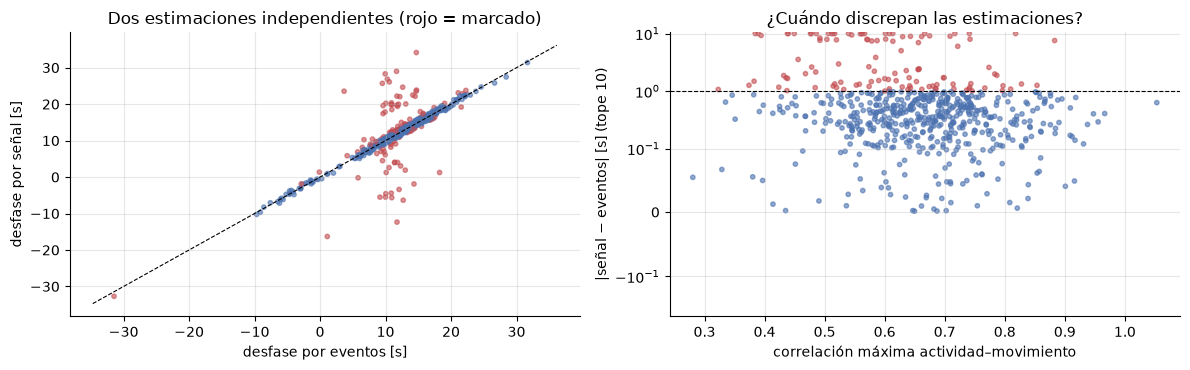

In [7]:
meta_df = pd.DataFrame(metas)
val_rows = []
for m in metas:
    for side in m["sides"]:
        val_rows.append({"mvnx_file": m["mvnx_file"], "brazo": side, "desfase eventos [s]": m[f"offset_event_{side}_s"],
                         "desfase señal [s]": m[f"offset_signal_{side}_s"], "diferencia [s]": m[f"diff_signal_event_{side}_s"],
                         "correlación": m[f"corr_signal_{side}"]})
validation = pd.DataFrame(val_rows)
validation["dudosa"] = validation["diferencia [s]"].abs() > VALIDATION_FLAG_S
flagged = set(validation.loc[validation["dudosa"], "mvnx_file"])
print(f"Pares con |señal − eventos| ≤ {VALIDATION_FLAG_S} s: {(~validation['dudosa']).sum()} de {len(validation)} "
      f"({(~validation['dudosa']).mean():.0%}) | ensayos marcados: {len(flagged)}")
display(validation[["diferencia [s]", "correlación"]].describe().round(3))
display(pd.DataFrame({f"umbral {u} s": {"pares marcados": int((validation["diferencia [s]"].abs() > u).sum()),
                                        "ensayos marcados": validation.loc[validation["diferencia [s]"].abs() > u, "mvnx_file"].nunique()}
                      for u in (0.25, 0.5, 1.0, 2.0, 5.0)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(validation["desfase eventos [s]"], validation["desfase señal [s]"], s=10, alpha=0.6,
                c=np.where(validation["dudosa"], "#c44e52", "#4c72b0"))
lims = [validation[["desfase eventos [s]", "desfase señal [s]"]].min().min() - 2, validation[["desfase eventos [s]", "desfase señal [s]"]].max().max() + 2]
axes[0].plot(lims, lims, "k--", lw=0.8)
axes[0].set(xlabel="desfase por eventos [s]", ylabel="desfase por señal [s]", title="Dos estimaciones independientes (rojo = marcado)")
axes[1].scatter(validation["correlación"], validation["diferencia [s]"].abs().clip(upper=10), s=10, alpha=0.6,
                c=np.where(validation["dudosa"], "#c44e52", "#4c72b0"))
axes[1].axhline(VALIDATION_FLAG_S, color="k", ls="--", lw=0.8)
axes[1].set_yscale("symlog", linthresh=0.1)
axes[1].set(xlabel="correlación máxima actividad–movimiento",
            ylabel="|señal − eventos| [s] (tope 10)", title="¿Cuándo discrepan las estimaciones?")
plt.tight_layout()
plt.show()

# 7. Ensamblar y exportar los dos conjuntos

Los ensayos se concatenan en dos conjuntos, `un_brazo` y `bimanual`:

- **`offsets`** marca dónde empieza cada ensayo, igual que la exportación del avance 2.
- **Columnas MVNX:** son la **unión** de las de todas las grabaciones. Donde una grabación no tiene una variable (por ejemplo, `jointAngleErgoXZY` en los sujetos 1, 11 y 13), la columna queda vacía (NaN).
- **Etiquetas:** se guardan `label_mvnx`, `label_emg` (o `label_emg_L` y `label_emg_R` en los bimanuales) y `labels_agree`. Esta última vale `True` cuando todas las etiquetas presentes en ese instante existen y coinciden.

In [8]:
def assemble(conjunto):
    rows = aligned[aligned["conjunto"] == conjunto]
    all_cols = []
    for m in (meta_by_file[f] for f in rows["mvnx_file"]):
        all_cols += [c for c in m["columns"] if c not in all_cols]
    order = sorted(all_cols, key=lambda c: (FIELD_ORDER.index(c.split("__")[0]), all_cols.index(c)))
    col_idx = {c: i for i, c in enumerate(order)}
    sides = ["L", "R"] if conjunto == "bimanual" else ["arm"]
    parts = {k: [] for k in ("time_s", "emg", "mvnx", "label_mvnx", *[f"label_emg_{s}" for s in sides])}
    trial_rows, offsets = [], [0]
    for r in rows.itertuples(index=False):
        m = meta_by_file[r.mvnx_file]
        with np.load(TRIAL_CACHE / f"{Path(r.mvnx_file).stem}.npz") as z:
            mv = np.full((m["n_steps"], len(order)), np.nan, dtype=np.float32)
            mv[:, [col_idx[c] for c in m["columns"]]] = z["mvnx"]
            parts["time_s"].append(z["time_s"])
            parts["emg"].append(z["emg"])
            parts["mvnx"].append(mv)
            parts["label_mvnx"].append(z["label_mvnx"])
            for s in sides:
                parts[f"label_emg_{s}"].append(z[f"label_emg_{r.side if s == 'arm' else s}"])
        offsets.append(offsets[-1] + m["n_steps"])
        info = {"trial_idx": len(trial_rows), "mvnx_file": r.mvnx_file, "subject": r.subject, "task": r.task, "side": r.side,
                "load_kg": r.load_kg, "condition": r.condition,
                "split": next(k for k, v in SPLITS.items() if r.subject in v),
                "offset": offsets[-2], "n_steps": m["n_steps"], "duration_s": m["duration_s"], "fs_mv_real": m["fs_mv_real"],
                "validacion_dudosa": r.mvnx_file in flagged}
        for s in m["sides"]:
            info.update({f"emg_file_{s}": m[f"emg_file_{s}"], f"fs_emg_{s}": m[f"fs_emg_{s}"],
                         f"desfase_eventos_{s}_s": m[f"offset_event_{s}_s"], f"desfase_senal_{s}_s": m[f"offset_signal_{s}_s"],
                         f"correlacion_senal_{s}": m[f"corr_signal_{s}"],
                         f"residuo_p95_{s}_ms": getattr(r, f"residual_p95_ms_{s}_base{MV_BASE}")})
        trial_rows.append(info)
    arrays = {k: np.concatenate(v) for k, v in parts.items()}
    labels = [arrays[f"label_emg_{s}"] for s in sides] + [arrays["label_mvnx"]]
    arrays["labels_agree"] = np.all([l >= 0 for l in labels], axis=0) & np.all([l == labels[0] for l in labels], axis=0)
    if conjunto != "bimanual":
        arrays["label_emg"] = arrays.pop("label_emg_arm")
    arrays["offsets"] = np.asarray(offsets, dtype=np.int64)
    emg_cols = ([f"L_{c}" for c in NORM_RMS] + [f"R_{c}" for c in NORM_RMS]) if conjunto == "bimanual" else NORM_RMS
    return arrays, pd.DataFrame(trial_rows), emg_cols, order


meta_by_file = {m["mvnx_file"]: m for m in metas}
summary = {}
for conjunto in ("un_brazo", "bimanual"):
    if not (aligned["conjunto"] == conjunto).any():
        continue
    arrays, trial_table, emg_cols, mv_cols = assemble(conjunto)
    out = EXPORT_DIR / conjunto
    out.mkdir(exist_ok=True)
    np.savez_compressed(out / "series.npz", **arrays)
    trial_table.to_csv(out / "trials.csv", index=False)
    (out / "columns.json").write_text(json.dumps({
        "emg": [{"name": c, "unit": "%MVC"} for c in emg_cols],
        "mvnx": [{"name": c, "field": c.split("__")[0], "kind": FIELD_KIND[c.split("__")[0]], "unit": FIELD_UNIT[c.split("__")[0]]}
                 for c in mv_cols]}, ensure_ascii=False, indent=1))
    size_mb = sum(f.stat().st_size for f in out.iterdir()) / 1e6
    summary[conjunto] = {"ensayos": len(trial_table), "sujetos": trial_table["subject"].nunique(), "pasos": int(arrays["offsets"][-1]),
                         "horas": arrays["offsets"][-1] / TARGET_FS / 3600, "canales sEMG": len(emg_cols), "columnas MVNX": len(mv_cols),
                         "MVNX con NaN": int(np.isnan(arrays["mvnx"]).any(axis=0).sum()),
                         "etiquetas coinciden": float(arrays["labels_agree"].mean()), "marcados": int(trial_table["validacion_dudosa"].sum()),
                         "MB": size_mb}
    print(f"{conjunto}: exportado en {out.relative_to(REPO_DIR)}")

exclusions.drop_duplicates().to_csv(EXPORT_DIR / "exclusiones.csv", index=False)
(EXPORT_DIR / "metadata.json").write_text(json.dumps({
    "target_fs": TARGET_FS, "reloj_de_referencia": "MVNX (marcas de tiempo reales de los frames, s desde el primer frame normal)",
    "alineacion": "desfase constante por par, mediana de los desfases de inicio y fin de cada segmento etiquetado",
    "base_indices_mvnx": MV_BASE, "base_indices_mvnx_motivo": base_reason,
    "antialias": {"ratio": ANTIALIAS_RATIO, "orden": ANTIALIAS_ORDER, "corte_hz": ANTIALIAS_RATIO * TARGET_FS,
                  "semg_solo_si_fs_menor_a": EMG_ANTIALIAS_BELOW_FS},
    "validacion": {"fs": VALIDATION_FS, "max_lag_s": VALIDATION_MAX_LAG_S, "umbral_marca_s": VALIDATION_FLAG_S},
    "label_order": LABEL_ORDER, "sin_etiqueta": -1, "splits": {k: list(v) for k, v in SPLITS.items()},
    "conjuntos": summary}, ensure_ascii=False, indent=1, default=float))
display(pd.DataFrame(summary).T.round(3))

un_brazo: exportado en notebooks/_cache/sync/fs12/un_brazo
bimanual: exportado en notebooks/_cache/sync/fs12/bimanual


,ensayos,sujetos,pasos,horas,canales sEMG,columnas MVNX,MVNX con NaN,etiquetas coinciden,marcados,MB
un_brazo,383.0,14.0,244388.0,5.657,8.0,782.0,24.0,0.838,87.0,705.168
bimanual,122.0,14.0,90819.0,2.102,16.0,782.0,24.0,0.886,23.0,265.931


# 8. Comprobaciones del resultado

### 8.1 ¿Coinciden las etiquetas de ambas fuentes, instante a instante?

Si la alineación es correcta, en cada instante la etiqueta sEMG y la MVNX deberían ser la misma actividad. La matriz muestra, para cada actividad según el sEMG, qué actividad marca el MVNX en ese mismo instante, sólo en los instantes etiquetados en ambas. Una diagonal cercana a 1 confirma que las dos fuentes quedaron alineadas.

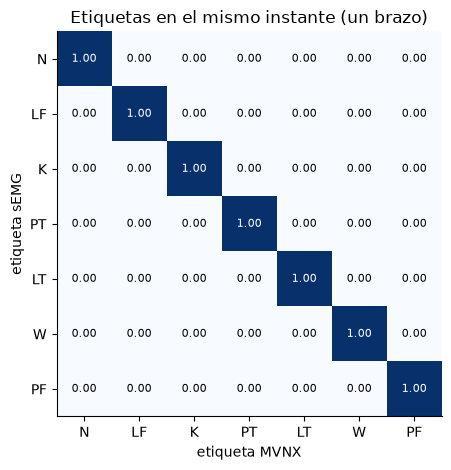

Instantes con ambas etiquetas: 84% | de ellos, con la misma actividad: 100.0%


In [9]:
z = np.load(EXPORT_DIR / "un_brazo" / "series.npz")
both = (z["label_emg"] >= 0) & (z["label_mvnx"] >= 0)
cm = pd.crosstab(pd.Series(z["label_emg"][both], name="sEMG").map(dict(enumerate(LABEL_ORDER))),
                 pd.Series(z["label_mvnx"][both], name="MVNX").map(dict(enumerate(LABEL_ORDER))), normalize="index")
cm = cm.reindex(index=LABEL_ORDER, columns=LABEL_ORDER).fillna(0)
fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(7), yticks=range(7), xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER, xlabel="etiqueta MVNX",
       ylabel="etiqueta sEMG", title="Etiquetas en el mismo instante (un brazo)")
ax.grid(False)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm.iloc[i, j] > 0.5 else "black")
plt.tight_layout()
plt.show()
print(f"Instantes con ambas etiquetas: {both.mean():.0%} | de ellos, con la misma actividad: {(z['label_emg'][both] == z['label_mvnx'][both]).mean():.1%}")

### 8.2 Un ensayo de ejemplo

Señales de un ensayo MMH ya alineadas en la rejilla común:

- **arriba:** la actividad muscular (promedio de los canales `Norm_RMS`);
- **en medio:** la altura de las manos (MVNX);
- **abajo:** las etiquetas de ambas fuentes.

Si la alineación es correcta, los aumentos de actividad muscular coinciden con los cambios de altura de las manos (levantar, colocar) y las dos franjas de etiquetas cambian al mismo tiempo.

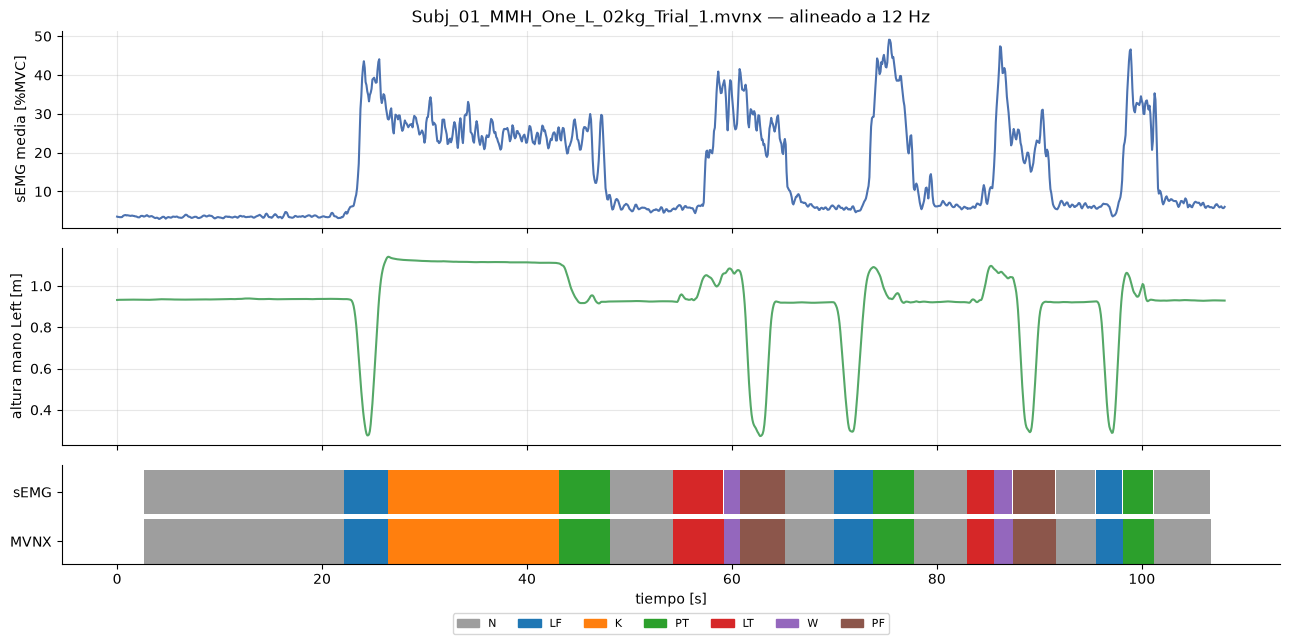

In [10]:
trials_1 = pd.read_csv(EXPORT_DIR / "un_brazo" / "trials.csv")
cols_1 = json.loads((EXPORT_DIR / "un_brazo" / "columns.json").read_text())
mv_names = [c["name"] for c in cols_1["mvnx"]]
example = trials_1[trials_1["task"] == "MMH_One"].iloc[0]
sl = slice(int(example["offset"]), int(example["offset"] + example["n_steps"]))
t = z["time_s"][sl] - z["time_s"][sl][0]
hand = "Left" if example["side"] == "L" else "Right"
colors = {"N": "#9e9e9e", "LF": "#1f77b4", "K": "#ff7f0e", "PT": "#2ca02c", "LT": "#d62728", "W": "#9467bd", "PF": "#8c564b"}

fig, axes = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})
axes[0].plot(t, z["emg"][sl].mean(axis=1), color="#4c72b0")
axes[0].set(ylabel="sEMG media [%MVC]", title=f"{example['mvnx_file']} — alineado a {TARGET_FS} Hz")
axes[1].plot(t, z["mvnx"][sl][:, mv_names.index(f"position__{hand}Hand__z")], color="#55a868")
axes[1].set(ylabel=f"altura mano {hand} [m]")
for row, key in ((1, "label_emg"), (0, "label_mvnx")):
    lab = z[key][sl]
    for k in range(len(t) - 1):
        if lab[k] >= 0:
            axes[2].fill_between([t[k], t[k + 1]], row, row + 0.9, color=colors[LABEL_ORDER[lab[k]]], lw=0)
axes[2].set(yticks=[0.45, 1.45], yticklabels=["MVNX", "sEMG"], xlabel="tiempo [s]", ylim=(0, 2))
axes[2].grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[2].legend(handles, colors.keys(), ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout()
plt.show()

# 9. Cómo usar la exportación (por ejemplo, en CPC)

`load_sync` lee un conjunto. Para tomar una ventana de un ensayo se usa `offsets`, igual que con la exportación del avance 2.

**Notas para el modelado:**

- **Escala:** las señales están **sin escalar** (%MVC, m, °, ...). Cada modelo debe ajustar su propio escalado **sólo con los sujetos de entrenamiento** (`split == "train"`).
- **NaN:** las columnas MVNX con NaN (variables ausentes en algunas grabaciones) deben eliminarse o imputarse antes de entrenar.
- **Ángulos y cuaterniones:** conviene representarlos sin discontinuidades, por ejemplo con seno y coseno para los ángulos.
- **Ensayos marcados:** `trials.csv` indica en `validacion_dudosa` los ensayos cuyo desfase no confirmó la señal. Conviene evaluar si excluirlos cambia los resultados.

In [11]:
def load_sync(conjunto, fs=TARGET_FS, base_dir=None):
    """Lee un conjunto exportado: series (dict de arreglos), trials (DataFrame) y columns (nombres y unidades)."""
    base = (base_dir or CACHE_DIR / "sync" / f"fs{fs}") / conjunto
    with np.load(base / "series.npz") as z:
        series = {k: z[k] for k in z.files}
    return series, pd.read_csv(base / "trials.csv"), json.loads((base / "columns.json").read_text())


series, trial_table, columns = load_sync("un_brazo", base_dir=EXPORT_DIR)

# Ejemplo: una ventana de 4 s que termina en el instante 300 del primer ensayo de entrenamiento
row = trial_table[trial_table["split"] == "train"].iloc[0]
win = 4 * TARGET_FS
end = int(row["offset"]) + min(300, int(row["n_steps"]) - 1)
emg_window = series["emg"][end - win + 1:end + 1]          # (pasos, 8)
mvnx_window = series["mvnx"][end - win + 1:end + 1]        # (pasos, columnas MVNX)
label = series["label_emg"][end]                            # etiqueta del instante final (convención del avance 2)
print(f"Ventana de {win} pasos | sEMG {emg_window.shape} | MVNX {mvnx_window.shape} | etiqueta final: "
      f"{LABEL_ORDER[label] if label >= 0 else 'sin etiqueta'}")

Ventana de 48 pasos | sEMG (48, 8) | MVNX (48, 782) | etiqueta final: LT


# 10. Resumen

*Cifras de la ejecución con `TARGET_FS = 12` Hz.*

| | Un brazo | Bimanual |
| :--- | :---: | :---: |
| Ensayos exportados | 383 | 122 |
| Horas alineadas | 5.7 | 2.1 |
| Canales sEMG | 8 | 16 |
| Columnas MVNX | 782 (24 con NaN) | 782 (24 con NaN) |
| Entrenamiento / validación / prueba | 275 / 54 / 54 | 87 / 18 / 17 |
| Marcados por la validación con señal | 87 (23 %) | 23 (19 %) |

- **Emparejamiento:** los 517 MVNX tienen su sEMG (643 archivos). Se excluyen **12 ensayos**: 3 bimanuales del sujeto 7 por canales rotos, 2 por etiquetas inconsistentes y 7 por saltos de tiempo en el MVNX.
- **Alineación por eventos:** un desfase constante por par explica **todos** los inicios y fines de actividad. El residuo típico es 0.5 ms y el p95 máximo 2 ms, es decir, menos de un frame MVNX (4 ms) y muy por debajo de un paso de la rejilla (83 ms).
- **Etiquetas:** donde ambas fuentes tienen etiqueta (84 % de los instantes), coinciden en el **100 %**: las dos fuentes quedaron alineadas.
- **Validación con la señal:** confirma el desfase dentro de ±1 s en el **82 %** de los pares. Los ensayos marcados:
  - se reparten entre todos los sujetos;
  - son más frecuentes en las tareas isocinéticas (27 %) que en las MMH (17 %).

  Ese patrón apunta a una limitación de la señal usada para validar (movimientos cíclicos con pocos cambios de postura), más que a un error de alineación. Aun así, conviene comprobar si excluirlos cambia los resultados del modelado.
- **Base de los índices MVNX:** ninguna etiqueta empieza en el frame 0 ni termina en el último, así que los datos no la determinan. Se usó base 0; el error máximo posible es de 1 frame (~4 ms).